
# Modelado estadístico de factores clínicos asociados al fracaso terapéutico en procedimientos SpyGlass

**Proyecto:** SpyGlass  
**Metodología:** Regresión logística penalizada de Firth  
**Enfoque:** Evaluación de la asociación entre indicaciones clínicas y fracaso terapéutico  

**Autores:** Miguel Ángel Pérez Vargas [✉](mailto:vargasmiguel@uninorte.edu.co), Paula Gómez Vargas [✉](mailto:apaulag@uninorte.edu.co)

## 1. Introducción

La colangioscopia asistida por SpyGlass permite la visualización directa de la vía biliar y facilita el diagnóstico y tratamiento de diferentes enfermedades biliopancreáticas. Su utilización resulta especialmente relevante en procedimientos de mayor complejidad, como aquellos relacionados con estenosis biliares, obstrucciones y lesiones de posible origen neoplásico. Sin embargo, el éxito terapéutico puede variar según las características clínicas y las condiciones que motivan la intervención.

En este contexto, identificar los factores asociados al fracaso terapéutico constituye una pregunta relevante para comprender los resultados de los procedimientos y reconocer situaciones clínicas que podrían representar mayores dificultades durante el tratamiento.

El presente estudio tiene como objetivo evaluar la asociación entre la presencia de estenosis u obstrucción biliar, la neoplasia o sospecha neoplásica y el fracaso terapéutico en la cohorte institucional de procedimientos SpyGlass de la Clínica de la Costa. Para ello, se construye un indicador que representa el número de estas condiciones registradas en cada procedimiento, permitiendo examinar si su presencia acumulada se relaciona con una mayor frecuencia de fracaso.

El análisis se desarrolla mediante regresión logística penalizada de Firth, considerando un modelo sin ajustar y otro ajustado por edad y sexo. Esta metodología permite reducir el sesgo de estimación asociado con muestras pequeñas y ofrece una alternativa para el análisis de desenlaces binarios cuando algunas categorías presentan un número limitado de eventos.

Dado el carácter retrospectivo y observacional de la información, así como la selección exploratoria de las indicaciones consideradas, los resultados se interpretarán como asociaciones estadísticas generadoras de hipótesis y no como relaciones causales o evidencia confirmatoria.


## 2. Preparación de datos

### 2.1 Librerías y environment

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import display, Markdown
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RUTA_PROYECTO = Path(r"C:\Users\USER\Desktop\SpyGlass")

RUTA_DATOS = RUTA_PROYECTO / "data"
RUTA_NOTEBOOKS = RUTA_PROYECTO / "notebooks"
RUTA_SRC = RUTA_PROYECTO / "src"
RUTA_SALIDA = RUTA_PROYECTO / "salidas_modelado"

sys.path.insert(0, str(RUTA_SRC))

from eda_toolkit import *

HOJA = 0
N_ESPERADO = 145
SEMILLA = 2026
ALFA = 0.05

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

### 2.2 Carga de la cohorte analítica

In [2]:
ruta_archivo = RUTA_DATOS / "dataset_limpio_v2.xlsx"

df_spyglass = pd.read_excel(ruta_archivo, sheet_name=HOJA)

df_spyglass = (
    df_spyglass.loc[df_spyglass["ID procedimiento"] != 153]
    .copy()
    .reset_index(drop=True)
)

assert len(df_spyglass) == N_ESPERADO, (
    f"Se esperaban {N_ESPERADO} registros, "
    f"pero se encontraron {len(df_spyglass)}."
)

print(f"Dimensiones de la cohorte analítica: {df_spyglass.shape}")

Dimensiones de la cohorte analítica: (145, 81)



### 2.3. Definición de la variable respuesta

La variable respuesta del análisis corresponde al **fracaso terapéutico** registrado durante los procedimientos de CPRE asistidos por SpyGlass. Este desenlace se representa mediante una variable binaria, asignando el valor 1 a los procedimientos con fracaso terapéutico y 0 a aquellos sin fracaso registrado.

Antes de desarrollar los modelos estadísticos, se verifica la distribución original del desenlace, su correcta codificación y la ausencia de valores faltantes o categorías no reconocidas. Esta comprobación permite establecer el número de eventos disponibles y garantizar la consistencia de la variable utilizada en los análisis posteriores.


In [3]:

columna_respuesta = "FRACASO TERAPEUTICO"

df_spyglass["FRACASO_MODELO"] = (
    df_spyglass[columna_respuesta]
    .astype("string")
    .str.strip()
    .str.upper()
    .map({"SI": 1, "NO": 0})
)

assert df_spyglass["FRACASO_MODELO"].notna().all(), (
    "Existen valores faltantes o categorías no reconocidas."
)

tabla_respuesta = (
    df_spyglass["FRACASO_MODELO"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("Fracaso terapéutico")
    .reset_index(name="Frecuencia")
)

tabla_respuesta["Porcentaje (%)"] = (
    100 * tabla_respuesta["Frecuencia"] / len(df_spyglass)
)

tabla_respuesta["Categoría"] = (
    tabla_respuesta["Fracaso terapéutico"]
    .map({0: "Sin fracaso", 1: "Con fracaso"})
)

tabla_respuesta = tabla_respuesta[
    ["Categoría", "Frecuencia", "Porcentaje (%)"]
]

display(
    tabla_respuesta.style
    .hide(axis="index")
    .format({"Porcentaje (%)": "{:.1f}"})
    .set_caption("Distribución del fracaso terapéutico en la cohorte analítica")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)

assert int(df_spyglass["FRACASO_MODELO"].sum()) == 28




Categoría,Frecuencia,Porcentaje (%)
Sin fracaso,117,80.7
Con fracaso,28,19.3



La cohorte analítica está conformada por 145 procedimientos, de los cuales 117 (80.7 %) no registraron fracaso terapéutico y 28 (19.3 %) presentaron este desenlace. La variable respuesta no contiene valores faltantes ni categorías adicionales, por lo que los 145 procedimientos pueden incluirse en el análisis del desenlace.




### 2.4. Definición y construcción de las variables explicativas

Para evaluar los factores asociados al fracaso terapéutico, se consideran dos indicaciones clínicas: **estenosis u obstrucción biliar** y **neoplasia o sospecha neoplásica**. Ambas se encuentran registradas mediante indicadores binarios que permiten identificar su presencia o ausencia en cada procedimiento.

A partir de estas variables se construye `N_INDICACIONES`, un indicador ordinal que representa el número de condiciones presentes. Su valor es 0 cuando ninguna de las dos indicaciones está registrada, 1 cuando se presenta una de ellas y 2 cuando ambas están presentes.

Esta construcción permite estudiar si existe una tendencia en la frecuencia de fracaso terapéutico conforme aumenta el número de indicaciones consideradas. No obstante, el indicador no constituye una escala validada de gravedad clínica y su utilización responde a una hipótesis exploratoria identificada durante el análisis preliminar.

Adicionalmente, se incorporan la **edad** y el **sexo** como covariables de ajuste. La edad se expresa en unidades de diez años para facilitar la interpretación de los coeficientes, mientras que el sexo se codifica mediante una variable binaria que toma como referencia la categoría femenina.



In [4]:

indicaciones = [
    "IND_ESTENOSIS_U_OBSTRUCCION_BILIAR",
    "IND_NEOPLASIA_O_SOSPECHA"
]

for variable in indicaciones:
    df_spyglass[variable] = pd.to_numeric(
        df_spyglass[variable],
        errors="coerce"
    )

    assert df_spyglass[variable].notna().all()
    assert df_spyglass[variable].isin([0, 1]).all()

df_spyglass["N_INDICACIONES"] = (
    df_spyglass[indicaciones]
    .sum(axis=1)
    .astype(int)
)

df_spyglass["EDAD_10"] = (
    pd.to_numeric(df_spyglass["EDAD"], errors="coerce") / 10
)

df_spyglass["SEXO_MASCULINO"] = (
    df_spyglass["SEXO"]
    .astype("string")
    .str.strip()
    .str.upper()
    .map({"MASCULINO": 1, "FEMENINO": 0})
)

variables_modelo = [
    "FRACASO_MODELO",
    "N_INDICACIONES",
    "EDAD_10",
    "SEXO_MASCULINO"
]

tabla_variables = pd.DataFrame({
    "Variable": variables_modelo,
    "Disponibles": [
        df_spyglass[col].notna().sum()
        for col in variables_modelo
    ],
    "Faltantes": [
        df_spyglass[col].isna().sum()
        for col in variables_modelo
    ],
    "Valores distintos": [
        df_spyglass[col].nunique()
        for col in variables_modelo
    ]
})

tabla_variables["Completitud (%)"] = (
    100 * tabla_variables["Disponibles"] / len(df_spyglass)
)

display(
    tabla_variables.style
    .hide(axis="index")
    .format({"Completitud (%)": "{:.1f}"})
    .set_caption("Disponibilidad de la variable respuesta y los predictores")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)

assert df_spyglass[variables_modelo].notna().all().all()
assert df_spyglass["N_INDICACIONES"].isin([0, 1, 2]).all()


Variable,Disponibles,Faltantes,Valores distintos,Completitud (%)
FRACASO_MODELO,145,0,2,100.0
N_INDICACIONES,145,0,3,100.0
EDAD_10,145,0,59,100.0
SEXO_MASCULINO,145,0,2,100.0




La tabla muestra que las cuatro variables consideradas para el modelado presentan una completitud del 100 %, por lo que los 145 procedimientos de la cohorte analítica disponen de la información necesaria para ajustar los modelos propuestos, sin requerir exclusiones adicionales por valores faltantes.

La variable `FRACASO_MODELO` corresponde a una transformación de la variable original `FRACASO TERAPEUTICO`, registrada en la base de datos mediante las categorías «SI» y «NO». Durante la preparación de los datos, estas categorías se recodificaron como 1 (con fracaso terapéutico) y 0 (sin fracaso terapéutico), respectivamente. Esta variable constituye el desenlace binario del estudio y no forma parte de los predictores.

Por su parte, `N_INDICACIONES` es una variable construida a partir de los indicadores de estenosis u obstrucción biliar y neoplasia o sospecha neoplásica. Sus tres valores posibles (0, 1 y 2) representan el número de estas condiciones registradas en cada procedimiento. Las variables `EDAD_10` y `SEXO_MASCULINO` se incorporan como covariables de ajuste: la primera expresa la edad en décadas y la segunda identifica el sexo masculino, tomando el femenino como categoría de referencia.

La disponibilidad completa de estas variables permite conservar el tamaño de la cohorte en los modelos sin ajustar y ajustado. No obstante, esta condición no garantiza por sí sola la estabilidad de las estimaciones, que también depende del número de eventos y de su distribución entre las categorías de los predictores.



## 3. Modelado estadístico mediante regresión logística de Firth

Se emplea regresión logística penalizada de Firth para evaluar la asociación entre el número de indicaciones clínicas registradas y el fracaso terapéutico en los procedimientos SpyGlass.

Este método introduce una corrección basada en la información de Fisher que permite reducir el sesgo de las estimaciones de máxima verosimilitud, especialmente en muestras pequeñas o con un número limitado de eventos.

Se especifican dos modelos:

- **Modelo 1 (sin ajustar):** incluye únicamente el número de indicaciones clínicas como variable explicativa.
- **Modelo 2 (ajustado):** incorpora adicionalmente la edad, expresada en décadas, y el sexo como covariables de ajuste.

En ambos modelos, el desenlace corresponde a `FRACASO_MODELO`, codificado como 1 cuando se registra fracaso terapéutico y 0 en caso contrario.

El indicador `N_INDICACIONES` se incorpora como predictor numérico con valores entre 0 y 2. Esta especificación supone que cada indicación adicional produce el mismo cambio en el logaritmo de las odds de fracaso terapéutico, supuesto que deberá considerarse al interpretar los resultados.

La asociación se expresará mediante *odds ratios* (OR), intervalos de confianza del 95 % y p values.


In [5]:

y = df_spyglass["FRACASO_MODELO"].astype(int)

predictores_m1 = ["N_INDICACIONES"]

predictores_m2 = [
    "N_INDICACIONES",
    "EDAD_10",
    "SEXO_MASCULINO"
]

X_m1 = sm.add_constant(
    df_spyglass[predictores_m1].astype(float),
    has_constant="add"
)

X_m2 = sm.add_constant(
    df_spyglass[predictores_m2].astype(float),
    has_constant="add"
)

assert X_m1.notna().all().all()
assert X_m2.notna().all().all()
assert y.notna().all()

assert len(y) == len(X_m1) == len(X_m2) == 145

print(f"Procedimientos incluidos: {len(y)}")
print(f"Fracasos terapéuticos: {y.sum()}")
print(f"Predictores del modelo 1: {predictores_m1}")
print(f"Predictores del modelo 2: {predictores_m2}")
print(f"Dimensiones de X_m1: {X_m1.shape}")
print(f"Dimensiones de X_m2: {X_m2.shape}")


Procedimientos incluidos: 145
Fracasos terapéuticos: 28
Predictores del modelo 1: ['N_INDICACIONES']
Predictores del modelo 2: ['N_INDICACIONES', 'EDAD_10', 'SEXO_MASCULINO']
Dimensiones de X_m1: (145, 2)
Dimensiones de X_m2: (145, 4)




### 3.1. Implementación del estimador de Firth

La regresión logística convencional estima los coeficientes mediante la maximización de la función de log-verosimilitud. Sin embargo, cuando el número de eventos es limitado, las estimaciones pueden presentar sesgo y, en presencia de separación completa o cuasicompleta, algunos coeficientes pueden divergir.

Para reducir estos problemas, se utiliza la corrección de Firth, que incorpora una penalización basada en la información de Fisher:

$$
\ell_F(\boldsymbol{\beta}) =
\ell(\boldsymbol{\beta}) +
\frac{1}{2}\log\left|I(\boldsymbol{\beta})\right|
$$

donde $\ell(\boldsymbol{\beta})$ representa la log-verosimilitud logística ordinaria, $I(\boldsymbol{\beta})$ corresponde a la matriz de información de Fisher y $\boldsymbol{\beta}$ es el vector de coeficientes del modelo.

La estimación consiste en encontrar los coeficientes que maximizan esta función penalizada:

$$
\hat{\boldsymbol{\beta}}_F =
\underset{\boldsymbol{\beta}}{\operatorname{arg\,max}}
\ \ell_F(\boldsymbol{\beta})
$$

Para resolver este problema se emplea el algoritmo de optimización BFGS, que permite obtener numéricamente los parámetros estimados y verificar la convergencia del procedimiento.

La implementación se realiza sobre las matrices de diseño definidas anteriormente. Posteriormente, los coeficientes se transformarán en *odds ratios* y se calcularán intervalos de confianza y valores p mediante procedimientos de inferencia basados en la verosimilitud penalizada.



In [6]:

from scipy.optimize import minimize
from scipy.special import expit, log_expit

def logverosimilitud_firth(beta, X, y):
    eta = X @ beta
    p = expit(eta)
    w = p * (1 - p)

    informacion = X.T @ (w[:, None] * X)

    signo, logdet = np.linalg.slogdet(informacion)

    if signo <= 0 or not np.isfinite(logdet):
        return -np.inf

    loglik = np.sum(
        y * log_expit(eta)
        + (1 - y) * log_expit(-eta)
    )

    return float(loglik + 0.5 * logdet)


def ajustar_firth(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    if np.linalg.matrix_rank(X) != X.shape[1]:
        raise ValueError("La matriz de diseño no tiene rango completo.")

    def objetivo(beta):
        valor = logverosimilitud_firth(beta, X, y)
        return -valor if np.isfinite(valor) else 1e100

    resultado = minimize(
        objetivo,
        x0=np.zeros(X.shape[1]),
        method="BFGS",
        options={
            "maxiter": 5000,
            "gtol": 1e-6
        }
    )

    return {
        "coeficientes": resultado.x,
        "loglik_penalizada": -resultado.fun,
        "convergencia": resultado.success,
        "mensaje": resultado.message,
        "iteraciones": resultado.nit,
        "gradiente": np.linalg.norm(resultado.jac)
    }



### 3.2. Ajuste y verificación de convergencia de los modelos

Una vez implementado el estimador de Firth, se procede al ajuste de los dos modelos definidos previamente.

El **Modelo 1** evalúa la asociación entre el número de indicaciones clínicas y el fracaso terapéutico, sin incorporar covariables adicionales:

$$
\operatorname{logit}(p_i) =
\beta_0 + \beta_1 N_i
$$

El **Modelo 2** incorpora la edad y el sexo como covariables de ajuste:

$$
\operatorname{logit}(p_i) =
\beta_0 + \beta_1 N_i +
\beta_2 A_i + \beta_3 S_i
$$

donde $p_i$ representa la probabilidad de fracaso terapéutico del procedimiento $i$, $N_i$ corresponde al número de indicaciones clínicas registradas, $A_i$ representa la edad expresada en décadas y $S_i$ identifica el sexo masculino.

Los coeficientes se estiman mediante la maximización de la log-verosimilitud penalizada de Firth, utilizando el algoritmo BFGS.

Para verificar la estabilidad numérica del ajuste, se examinan el estado de convergencia, el número de iteraciones y la norma del gradiente de la función objetivo. Una convergencia satisfactoria constituye una condición necesaria para continuar con la interpretación de los parámetros estimados.


In [7]:

resultado_m1 = ajustar_firth(X_m1, y)
resultado_m2 = ajustar_firth(X_m2, y)

tabla_convergencia = pd.DataFrame([
    {
        "Modelo": "M1 - Sin ajustar",
        "Convergencia": "Sí" if resultado_m1["convergencia"] else "No",
        "Iteraciones": resultado_m1["iteraciones"],
        "Norma del gradiente": resultado_m1["gradiente"],
        "Log-verosimilitud penalizada": resultado_m1["loglik_penalizada"]
    },
    {
        "Modelo": "M2 - Ajustado",
        "Convergencia": "Sí" if resultado_m2["convergencia"] else "No",
        "Iteraciones": resultado_m2["iteraciones"],
        "Norma del gradiente": resultado_m2["gradiente"],
        "Log-verosimilitud penalizada": resultado_m2["loglik_penalizada"]
    }
])

display(
    tabla_convergencia.style
    .hide(axis="index")
    .format({
        "Norma del gradiente": "{:.2e}",
        "Log-verosimilitud penalizada": "{:.4f}"
    })
    .set_caption("Diagnóstico de convergencia de los modelos de Firth")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)


Modelo,Convergencia,Iteraciones,Norma del gradiente,Log-verosimilitud penalizada
M1 - Sin ajustar,Sí,7,0.00e+00,-65.8483
M2 - Ajustado,Sí,10,1.17e-06,-62.4459




Ambos modelos convergieron. El modelo sin ajustar alcanza la solución en 7 iteraciones, con una norma del gradiente prácticamente nula y una log-verosimilitud penalizada de -65.8483. Por su parte, el modelo ajustado converge en 10 iteraciones, con una norma del gradiente de aproximadamente $1.17 \times 10^{-6}$ y una log-verosimilitud penalizada de -62.4459.

Estos resultados indican que el procedimiento de optimización logra estimaciones numéricamente estables. Ambos modelos conservan los 145 procedimientos y los 28 eventos de fracaso terapéutico, lo que permite examinar la asociación principal antes y después del ajuste por edad y sexo.

La convergencia numérica no implica, por sí misma, significancia estadística ni garantiza la validez de los supuestos del modelo. Por tanto, el siguiente paso consiste en estimar e interpretar los coeficientes y sus correspondientes medidas de incertidumbre.



### 3.3. Estimación de coeficientes y odds ratios

Una vez verificada la convergencia de ambos modelos, se examinan los coeficientes estimados mediante la regresión logística penalizada de Firth.

Los coeficientes se transforman a *odds ratios* (OR) mediante la función exponencial:

$$
OR_j = \exp(\hat{\beta}_j)
$$

En el modelo sin ajustar, el OR asociado a `N_INDICACIONES` representa el cambio multiplicativo en las odds de fracaso terapéutico por cada indicación clínica adicional.

En el modelo ajustado, esta asociación se estima manteniendo constantes la edad y el sexo. Para la edad, el OR corresponde a un incremento de diez años, mientras que para el sexo representa la comparación entre masculino y femenino, utilizado como categoría de referencia.

En esta etapa se presentan las estimaciones puntuales. Posteriormente, se calcularán intervalos de confianza del 95 % y valores p mediante inferencia basada en la verosimilitud penalizada.


In [8]:

nombres_m1 = X_m1.columns.tolist()
nombres_m2 = X_m2.columns.tolist()

tabla_coeficientes = pd.concat(
    [
        pd.DataFrame({
            "Modelo": "M1 - Sin ajustar",
            "Variable": nombres_m1,
            "Coeficiente": resultado_m1["coeficientes"]
        }),
        pd.DataFrame({
            "Modelo": "M2 - Ajustado",
            "Variable": nombres_m2,
            "Coeficiente": resultado_m2["coeficientes"]
        })
    ],
    ignore_index=True
)

tabla_coeficientes["OR"] = np.exp(
    tabla_coeficientes["Coeficiente"]
)

tabla_coeficientes["Variable"] = tabla_coeficientes["Variable"].replace({
    "const": "Intercepto",
    "N_INDICACIONES": "Número de indicaciones",
    "EDAD_10": "Edad (por 10 años)",
    "SEXO_MASCULINO": "Sexo masculino"
})

display(
    tabla_coeficientes.style
    .hide(axis="index")
    .format({
        "Coeficiente": "{:.4f}",
        "OR": "{:.4f}"
    })
    .set_caption("Coeficientes y odds ratios estimados mediante regresión de Firth")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)


Modelo,Variable,Coeficiente,OR
M1 - Sin ajustar,Intercepto,-1.6855,0.1854
M1 - Sin ajustar,Número de indicaciones,0.7455,2.1075
M2 - Ajustado,Intercepto,-1.8283,0.1607
M2 - Ajustado,Número de indicaciones,0.7202,2.0549
M2 - Ajustado,Edad (por 10 años),-0.0012,0.9988
M2 - Ajustado,Sexo masculino,0.4551,1.5763




En el modelo sin ajustar, el número de indicaciones clínicas presenta un coeficiente positivo de 0.7455, correspondiente a un *odds ratio* (OR) de 2.1075. Esto indica que, por cada indicación adicional de estenosis u obstrucción biliar y neoplasia o sospecha neoplásica, las odds estimadas de fracaso terapéutico se multiplican aproximadamente por 2.11.

Al incorporar la edad y el sexo como covariables de ajuste, el OR asociado al número de indicaciones es de 2.0549. La similitud entre ambas estimaciones sugiere que la magnitud de la asociación observada cambia poco después de considerar estas características demográficas.

En cuanto a las covariables, la edad presenta un OR de 0.9988 por cada diez años adicionales, valor muy próximo a la unidad. El sexo masculino presenta un OR de 1.5763 respecto al femenino, lo que corresponde a mayores odds estimadas de fracaso terapéutico en los procedimientos registrados en hombres, manteniendo constantes las demás variables.

Estas estimaciones representan asociaciones estadísticas y no efectos causales. Además, el modelo supone un cambio constante en el logaritmo de las odds por cada indicación adicional, independientemente de cuál de las dos condiciones clínicas esté presente.

Aunque los resultados muestran una asociación positiva entre el número de indicaciones y el fracaso terapéutico, todavía es necesario examinar los intervalos de confianza y los p values para evaluar la precisión de las estimaciones y su evidencia estadística.



### 3.4. Inferencia mediante verosimilitud penalizada perfilada

Una vez estimados los coeficientes y sus correspondientes *odds ratios*, se procede a evaluar la incertidumbre estadística mediante intervalos de confianza del 95 % y pruebas de hipótesis.

Para ello, se utiliza la **verosimilitud penalizada perfilada**, que permite evaluar cada coeficiente mientras los demás parámetros del modelo se reestiman. Este procedimiento resulta apropiado para complementar la estimación de Firth y evita depender exclusivamente de aproximaciones basadas en errores estándar de Wald.

El estadístico de razón de verosimilitudes penalizadas se define como:

$$
D_j(\beta_j)=2\left[\ell_F(\hat{\boldsymbol{\beta}}_F)
-\ell_{F,p}(\beta_j)
\right]
$$

donde $\ell_F(\hat{\boldsymbol{\beta}}_F)$ representa la log-verosimilitud penalizada del modelo completo y $\ell_{F,p}(\beta_j)$ corresponde a la log-verosimilitud penalizada perfilada al fijar el coeficiente de interés.

Los límites del intervalo de confianza del 95 % se determinan mediante:

$$D_j(\beta_j)=\chi^2_{1,0.95}$$

Los límites obtenidos se transforman mediante la función exponencial para expresarlos en la escala de *odds ratios*.

Para evaluar la hipótesis nula de ausencia de asociación, $H_0:\beta_j=0$, se utiliza el estadístico de razón de verosimilitudes penalizadas y su aproximación asintótica a una distribución chi-cuadrado con un grado de libertad.

Dado el tamaño de la cohorte y el carácter exploratorio del análisis, los intervalos de confianza y los valores p se interpretarán con cautela.


In [9]:

from scipy.optimize import brentq
from scipy.stats import chi2

def inferencia_firth(X, y, resultado, alpha=0.05):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    beta_hat = resultado["coeficientes"]
    loglik_max = logverosimilitud_firth(beta_hat, X, y)
    umbral = chi2.ppf(1 - alpha, df=1)

    if not resultado["convergencia"]:
        raise RuntimeError("El modelo no presenta convergencia satisfactoria.")

    resultados = []

    for j in range(X.shape[1]):
        indices_libres = np.arange(X.shape[1]) != j

        def perfil(valor):
            beta_inicial = beta_hat[indices_libres].copy()

            def objetivo(beta_libre):
                beta = np.empty(X.shape[1])
                beta[j] = valor
                beta[indices_libres] = beta_libre
                return -logverosimilitud_firth(beta, X, y)

            ajuste = minimize(
                objetivo,
                beta_inicial,
                method="BFGS",
                options={"maxiter": 5000, "gtol": 1e-6}
            )

            if not np.isfinite(ajuste.fun):
                raise RuntimeError("No se obtuvo un perfil finito.")

            return -ajuste.fun

        def estadistico(valor):
            return 2 * (loglik_max - perfil(valor))

        def diferencia(valor):
            return estadistico(valor) - umbral

        def buscar_limite(direccion):
            distancia = 0.5

            for _ in range(30):
                extremo = beta_hat[j] + direccion * distancia

                if diferencia(extremo) >= 0:
                    limites = sorted([beta_hat[j], extremo])
                    return brentq(
                        diferencia,
                        limites[0],
                        limites[1],
                        xtol=1e-7
                    )

                distancia *= 1.5

            raise RuntimeError(
                f"No se encontró un límite para el coeficiente {j}."
            )

        limite_inferior = buscar_limite(-1)
        limite_superior = buscar_limite(1)

        estadistico_nulo = max(0, estadistico(0))
        valor_p = chi2.sf(estadistico_nulo, df=1)

        resultados.append({
            "Coeficiente": beta_hat[j],
            "OR": np.exp(beta_hat[j]),
            "IC 95 % inferior": np.exp(limite_inferior),
            "IC 95 % superior": np.exp(limite_superior),
            "Valor p": valor_p
        })

    return pd.DataFrame(resultados)


In [10]:

inferencia_m1 = inferencia_firth(
    X_m1, y, resultado_m1, alpha=ALFA
)

inferencia_m2 = inferencia_firth(
    X_m2, y, resultado_m2, alpha=ALFA
)

inferencia_m1.insert(0, "Variable", X_m1.columns)
inferencia_m1.insert(0, "Modelo", "M1 - Sin ajustar")

inferencia_m2.insert(0, "Variable", X_m2.columns)
inferencia_m2.insert(0, "Modelo", "M2 - Ajustado")

tabla_inferencia = pd.concat(
    [inferencia_m1, inferencia_m2],
    ignore_index=True
)

tabla_inferencia["Variable"] = tabla_inferencia["Variable"].replace({
    "const": "Intercepto",
    "N_INDICACIONES": "Número de indicaciones",
    "EDAD_10": "Edad (por 10 años)",
    "SEXO_MASCULINO": "Sexo masculino"
})

tabla_inferencia["IC 95 %"] = tabla_inferencia.apply(
    lambda fila: (
        f'{fila["IC 95 % inferior"]:.3f} – '
        f'{fila["IC 95 % superior"]:.3f}'
    ),
    axis=1
)

tabla_inferencia["Significativo"] = np.where(
    tabla_inferencia["Valor p"] < ALFA,
    "Sí",
    "No"
)

tabla_inferencia_final = tabla_inferencia[
    [
        "Modelo",
        "Variable",
        "OR",
        "IC 95 %",
        "Valor p",
        "Significativo"
    ]
].copy()

display(
    tabla_inferencia_final.style
    .hide(axis="index")
    .format({
        "OR": "{:.3f}",
        "Valor p": "{:.4f}"
    })
    .set_caption(
        "Resultados inferenciales de los modelos de regresión logística de Firth"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)



Modelo,Variable,OR,IC 95 %,Valor p,Significativo
M1 - Sin ajustar,Intercepto,0.185,0.110 – 0.297,0.0000,Sí
M1 - Sin ajustar,Número de indicaciones,2.107,1.132 – 3.905,0.0195,Sí
M2 - Ajustado,Intercepto,0.161,0.036 – 0.637,0.0087,Sí
M2 - Ajustado,Número de indicaciones,2.055,1.077 – 3.896,0.0296,Sí
M2 - Ajustado,Edad (por 10 años),0.999,0.768 – 1.299,0.9931,No
M2 - Ajustado,Sexo masculino,1.576,0.678 – 3.634,0.2867,No



Los resultados de la inferencia mediante verosimilitud penalizada perfilada muestran una asociación positiva entre el número de indicaciones clínicas y el fracaso terapéutico.

En el modelo sin ajustar, el número de indicaciones presenta un OR de 2.107 (IC del 95 %: 1.132–3.905; p = 0.0195). Esto indica que cada indicación adicional se asocia con un incremento multiplicativo de aproximadamente 2.11 en las odds de fracaso terapéutico.

En el modelo ajustado por edad y sexo, la asociación se mantiene, con un OR de 2.055 (IC del 95 %: 1.077–3.896; p = 0.0296). La similitud entre las estimaciones de ambos modelos sugiere que la asociación observada presenta poca variación después de incorporar las covariables demográficas consideradas.

Por otra parte, la edad presenta un OR de 0.999 por cada diez años adicionales (IC del 95 %: 0.768–1.299; p = 0.9931), sin evidencia estadística de asociación con el desenlace. El sexo masculino presenta un OR de 1.576 respecto al femenino (IC del 95 %: 0.678–3.634; p = 0.2867), aunque su intervalo de confianza incluye la unidad y tampoco se identifica una asociación estadísticamente significativa.

Los resultados muestran evidencia estadística exploratoria de una asociación entre el número de indicaciones clínicas consideradas y el fracaso terapéutico. Sin embargo, la amplitud de los intervalos de confianza refleja incertidumbre en la magnitud de las asociaciones.

Estos hallazgos deben interpretarse considerando el tamaño de la cohorte, los 28 eventos registrados y la construcción exploratoria del indicador `N_INDICACIONES`. Asimismo, el modelo supone un efecto constante por cada indicación adicional y no permite distinguir el efecto individual de cada condición clínica. Por tanto, los resultados no establecen relaciones causales ni constituyen evidencia confirmatoria independiente.



#### 3.4.1. Visualización de las asociaciones estimadas

Se presentan los *odds ratios* y sus intervalos de confianza del 95 % para los tres modelos de regresión logística de Firth. Esta representación permite comparar la magnitud y dirección de las asociaciones, así como la incertidumbre de las estimaciones obtenidas mediante verosimilitud penalizada perfilada.


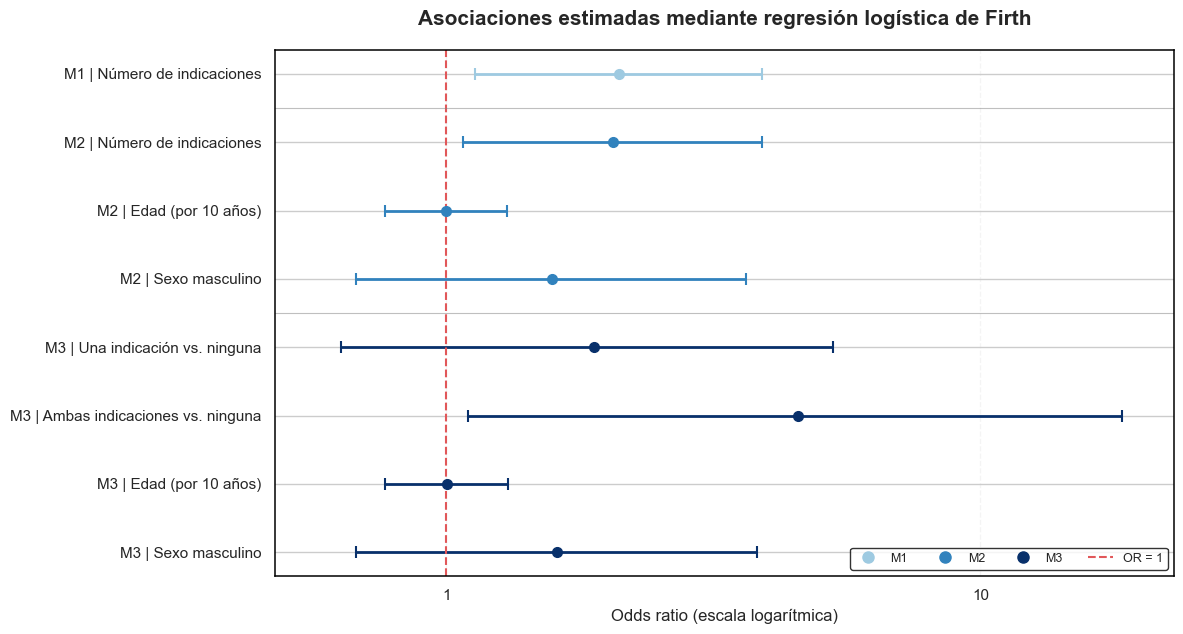

In [21]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

datos_forest = pd.concat([
    inferencia_m1.assign(Modelo="M1"),
    inferencia_m2.assign(Modelo="M2"),
    inferencia_m3.assign(Modelo="M3")
], ignore_index=True)

nombres_variables = {
    "const": "Intercepto",
    "Intercepto": "Intercepto",
    "N_INDICACIONES": "Número de indicaciones",
    "EDAD_10": "Edad (por 10 años)",
    "SEXO_MASCULINO": "Sexo masculino",
    "IND_UNA": "Una indicación vs. ninguna",
    "IND_AMBAS": "Ambas indicaciones vs. ninguna"
}

datos_forest["Variable"] = (
    datos_forest["Variable"]
    .replace(nombres_variables)
)

datos_forest = datos_forest[
    datos_forest["Variable"] != "Intercepto"
].copy()

orden_variables = [
    ("M1", "Número de indicaciones"),
    ("M2", "Número de indicaciones"),
    ("M2", "Edad (por 10 años)"),
    ("M2", "Sexo masculino"),
    ("M3", "Una indicación vs. ninguna"),
    ("M3", "Ambas indicaciones vs. ninguna"),
    ("M3", "Edad (por 10 años)"),
    ("M3", "Sexo masculino")
]

orden = {
    clave: i
    for i, clave in enumerate(orden_variables)
}

datos_forest["Orden"] = [
    orden.get((modelo, variable), len(orden))
    for modelo, variable in zip(
        datos_forest["Modelo"],
        datos_forest["Variable"]
    )
]

datos_forest = (
    datos_forest
    .sort_values("Orden")
    .reset_index(drop=True)
)

colores_forest = {
    "M1": "#9ECAE1",
    "M2": "#3182BD",
    "M3": "#08306B"
}

fig, ax = plt.subplots(figsize=(12, 6.5))

posiciones = np.arange(len(datos_forest))[::-1]

for posicion, (_, fila) in zip(posiciones, datos_forest.iterrows()):
    estimacion = fila["OR"]
    inferior = fila["IC 95 % inferior"]
    superior = fila["IC 95 % superior"]

    ax.errorbar(
        estimacion,
        posicion,
        xerr=np.array([
            [estimacion - inferior],
            [superior - estimacion]
        ]),
        fmt="o",
        color=colores_forest[fila["Modelo"]],
        ecolor=colores_forest[fila["Modelo"]],
        markersize=7,
        elinewidth=2,
        capsize=4,
        capthick=1.5
    )

ax.axvline(
    1,
    color="#E15759",
    linestyle="--",
    linewidth=1.5
)

ax.set_yticks(posiciones)
ax.set_yticklabels([
    f'{fila["Modelo"]} | {fila["Variable"]}'
    for _, fila in datos_forest.iterrows()
])

ax.set_xscale("log")

limite_inferior = datos_forest["IC 95 % inferior"].min()
limite_superior = datos_forest["IC 95 % superior"].max()

ax.set_xlim(
    limite_inferior * 0.75,
    limite_superior * 1.25
)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:g}")
)

ax.set_xlabel("Odds ratio (escala logarítmica)", fontsize=12)

ax.set_title(
    "Asociaciones estimadas mediante regresión logística de Firth",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.grid(axis="x", linestyle="--", alpha=0.20)

for i in range(1, len(datos_forest)):
    if datos_forest.loc[i, "Modelo"] != datos_forest.loc[i - 1, "Modelo"]:
        ax.axhline(
            len(datos_forest) - i - 0.5,
            color="gray",
            linewidth=0.8,
            alpha=0.5
        )

leyenda = [
    Line2D(
        [0], [0],
        marker="o",
        color=color,
        linestyle="None",
        markersize=8,
        label=modelo
    )
    for modelo, color in colores_forest.items()
]

leyenda.append(
    Line2D(
        [0], [0],
        color="#E15759",
        linestyle="--",
        linewidth=1.5,
        label="OR = 1"
    )
)

ax.legend(
    handles=leyenda,
    loc="lower right",
    frameon=True,
    edgecolor="black",
    ncol=4,
    fontsize=9
)

for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1.1)

plt.tight_layout()
plt.show()



El forest plot muestra que el número de indicaciones clínicas mantiene una asociación positiva con el fracaso terapéutico en los modelos M1 y M2. En ambas especificaciones, los *odds ratios* se sitúan por encima de 1 y sus intervalos de confianza del 95 % no incluyen la unidad, lo que respalda la asociación identificada en el análisis inferencial.

En M3, la asociación es más marcada para los procedimientos que presentan ambas indicaciones clínicas, cuyo intervalo de confianza también se mantiene por encima de 1. Por el contrario, la estimación correspondiente a una sola indicación presenta mayor incertidumbre y su intervalo incluye la unidad. La edad muestra un efecto cercano a 1 en los modelos ajustados, sin evidencia de una asociación estadísticamente significativa. El sexo masculino presenta estimaciones superiores a la unidad, pero con intervalos amplios que tampoco permiten establecer una asociación concluyente.

En general, el número de indicaciones clínicas es el predictor que muestra la asociación más consistente con el fracaso terapéutico. La amplitud de algunos intervalos, especialmente en M3, refleja la incertidumbre de las estimaciones al analizar categorías con un número reducido de observaciones.


### 3.5. Análisis de sensibilidad de la especificación del predictor principal

El modelo principal incorpora `N_INDICACIONES` como una variable numérica ordinal, suponiendo que cada indicación clínica adicional produce un cambio constante en el logaritmo de las odds de fracaso terapéutico.

Para examinar la influencia de este supuesto, se plantea un análisis de sensibilidad mediante una especificación categórica del indicador. En este modelo, los procedimientos sin ninguna de las dos indicaciones constituyen la categoría de referencia, mientras que la presencia de una o ambas indicaciones se representa mediante variables binarias independientes.

La especificación alternativa, ajustada por edad y sexo, es:

$$
\operatorname{logit}(p_i) =
\beta_0 +
\beta_1 I(N_i=1) +
\beta_2 I(N_i=2) +
\beta_3 A_i +
\beta_4 S_i
$$

donde $I(N_i=1)$ identifica los procedimientos con una indicación e $I(N_i=2)$ identifica aquellos con ambas indicaciones. Las variables $A_i$ y $S_i$ representan la edad en décadas y el sexo masculino, respectivamente.

Esta formulación permite estimar asociaciones diferenciadas para cada categoría, sin imponer una relación lineal entre el número de indicaciones y el logaritmo de las odds.

Dado que la categoría con ambas indicaciones contiene un número reducido de procedimientos, sus estimaciones pueden presentar una incertidumbre considerable. Por ello, el análisis se considera una evaluación complementaria de sensibilidad y no un sustituto automático del modelo principal.


In [11]:

df_spyglass["IND_UNA"] = (
    df_spyglass["N_INDICACIONES"] == 1
).astype(int)

df_spyglass["IND_AMBAS"] = (
    df_spyglass["N_INDICACIONES"] == 2
).astype(int)

predictores_m3 = [
    "IND_UNA",
    "IND_AMBAS",
    "EDAD_10",
    "SEXO_MASCULINO"
]

X_m3 = sm.add_constant(
    df_spyglass[predictores_m3].astype(float),
    has_constant="add"
)

assert X_m3.notna().all().all()
assert np.linalg.matrix_rank(X_m3.to_numpy()) == X_m3.shape[1]
assert len(X_m3) == len(y) == 145

resultado_m3 = ajustar_firth(X_m3, y)

tabla_m3 = pd.DataFrame({
    "Variable": X_m3.columns,
    "Coeficiente": resultado_m3["coeficientes"]
})

tabla_m3["OR"] = np.exp(tabla_m3["Coeficiente"])

tabla_m3["Variable"] = tabla_m3["Variable"].replace({
    "const": "Intercepto",
    "IND_UNA": "Una indicación vs. ninguna",
    "IND_AMBAS": "Ambas indicaciones vs. ninguna",
    "EDAD_10": "Edad (por 10 años)",
    "SEXO_MASCULINO": "Sexo masculino"
})

display(
    tabla_m3.style
    .hide(axis="index")
    .format({
        "Coeficiente": "{:.4f}",
        "OR": "{:.4f}"
    })
    .set_caption(
        "Modelo de Firth con especificación categórica del número de indicaciones"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)

print(f"Convergencia: {resultado_m3['convergencia']}")
print(f"Iteraciones: {resultado_m3['iteraciones']}")
print(f"Norma del gradiente: {resultado_m3['gradiente']:.2e}")
print(f"Mensaje del optimizador: {resultado_m3['mensaje']}")


Variable,Coeficiente,OR
Intercepto,-1.8406,0.1587
Una indicación vs. ninguna,0.6365,1.8899
Ambas indicaciones vs. ninguna,1.5183,4.5643
Edad (por 10 años),0.0028,1.0028
Sexo masculino,0.4776,1.6123


Convergencia: False
Iteraciones: 12
Norma del gradiente: 2.52e-06
Mensaje del optimizador: Desired error not necessarily achieved due to precision loss.



#### 3.5.1. Verificación de la estabilidad numérica del modelo alternativo

El ajuste inicial del modelo con especificación categórica presenta una advertencia de pérdida de precisión numérica durante la optimización mediante BFGS.

Aunque la norma del gradiente es pequeña, el algoritmo no declara convergencia satisfactoria. Por esta razón, antes de interpretar los coeficientes o calcular sus intervalos de confianza, se realiza una verificación adicional de la solución.

Para mejorar la estabilidad del procedimiento, se implementa el gradiente analítico de la log-verosimilitud penalizada de Firth, evitando depender de aproximaciones numéricas por diferencias finitas.

El vector de puntuaciones ajustadas se expresa como:

$$
U_F(\boldsymbol{\beta}) =
X^\top
\left[
\boldsymbol{y}-\boldsymbol{p}
+
\boldsymbol{h}\odot
\left(\frac{1}{2}-\boldsymbol{p}\right)
\right]
$$

donde $\boldsymbol{p}$ contiene las probabilidades estimadas, $\boldsymbol{h}$ representa los valores de influencia de la matriz sombrero ponderada y $\odot$ indica el producto elemento a elemento.

Esta formulación permite proporcionar directamente el gradiente al algoritmo BFGS y verificar si las estimaciones obtenidas inicialmente corresponden a una solución numéricamente estable.


In [12]:


def gradiente_firth(beta, X, y):
    eta = X @ beta
    p = expit(eta)
    w = p * (1 - p)

    informacion = X.T @ (w[:, None] * X)

    solucion = np.linalg.solve(informacion, X.T)

    influencia = w * np.sum(
        X * solucion.T,
        axis=1
    )

    puntuacion = X.T @ (
        y - p + influencia * (0.5 - p)
    )

    return puntuacion



def ajustar_firth_gradiente(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    if np.linalg.matrix_rank(X) != X.shape[1]:
        raise ValueError("La matriz de diseño no tiene rango completo.")

    def objetivo(beta):
        return -logverosimilitud_firth(beta, X, y)

    def gradiente(beta):
        return -gradiente_firth(beta, X, y)

    resultado = minimize(
        objetivo,
        x0=np.zeros(X.shape[1]),
        jac=gradiente,
        method="BFGS",
        options={
            "maxiter": 5000,
            "gtol": 1e-6
        }
    )

    return {
        "coeficientes": resultado.x,
        "loglik_penalizada": -resultado.fun,
        "convergencia": resultado.success,
        "mensaje": resultado.message,
        "iteraciones": resultado.nit,
        "gradiente": np.linalg.norm(resultado.jac)
    }


resultado_m3_verificado = ajustar_firth_gradiente(X_m3, y)

print(f"Convergencia: {resultado_m3_verificado['convergencia']}")
print(f"Iteraciones: {resultado_m3_verificado['iteraciones']}")
print(f"Norma del gradiente: {resultado_m3_verificado['gradiente']:.2e}")
print(f"Mensaje: {resultado_m3_verificado['mensaje']}")

print("\nComparación de coeficientes:")

tabla_verificacion = pd.DataFrame({
    "Variable": X_m3.columns,
    "Estimación inicial": resultado_m3["coeficientes"],
    "Estimación verificada": resultado_m3_verificado["coeficientes"]
})

tabla_verificacion["Diferencia absoluta"] = (
    tabla_verificacion["Estimación inicial"]
    - tabla_verificacion["Estimación verificada"]
).abs()

display(
    tabla_verificacion.style
    .hide(axis="index")
    .format({
        "Estimación inicial": "{:.6f}",
        "Estimación verificada": "{:.6f}",
        "Diferencia absoluta": "{:.2e}"
    })
    .set_caption("Verificación numérica de los coeficientes del modelo M3")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)


Convergencia: True
Iteraciones: 11
Norma del gradiente: 5.84e-08
Mensaje: Optimization terminated successfully.

Comparación de coeficientes:


Variable,Estimación inicial,Estimación verificada,Diferencia absoluta
const,-1.840639,-1.840640,5.67e-07
IND_UNA,0.636514,0.636514,6.85e-08
IND_AMBAS,1.518273,1.518273,2.15e-07
EDAD_10,0.002820,0.002820,1.11e-07
SEXO_MASCULINO,0.477632,0.477632,6.56e-08





La verificación numérica del modelo de regresión logística de Firth con especificación categórica muestra una convergencia satisfactoria después de 11 iteraciones, con una norma del gradiente de $5.84 \times 10^{-8}$. Este resultado indica que el procedimiento de optimización alcanza una solución estacionaria con un grado elevado de precisión numérica.

Al comparar las estimaciones iniciales con las obtenidas mediante el gradiente analítico, se observan diferencias absolutas inferiores a $10^{-6}$ en todos los coeficientes. La mayor diferencia corresponde al intercepto ($5.67 \times 10^{-7}$), mientras que las estimaciones de las variables explicativas permanecen prácticamente inalteradas.

Estos resultados sugieren que la advertencia de pérdida de precisión registrada durante el ajuste inicial responde a limitaciones numéricas del procedimiento de optimización y no a diferencias sustanciales en la solución estimada.

En consecuencia, se considera que el modelo alternativo presenta una solución numéricamente estable, lo que permite continuar con la estimación de intervalos de confianza y pruebas de hipótesis mediante verosimilitud penalizada perfilada.


#### 3.5.2. Inferencia del modelo con especificación categórica

Una vez verificada la convergencia del modelo alternativo, se calculan los intervalos de confianza del 95 % y los valores p mediante verosimilitud penalizada perfilada.

El análisis permite evaluar por separado la asociación entre el fracaso terapéutico y la presencia de una o ambas indicaciones clínicas, utilizando como referencia los procedimientos sin ninguna de las dos indicaciones.

Los resultados se presentan en términos de *odds ratios* e intervalos de confianza, manteniendo el ajuste por edad y sexo. Esta especificación constituye un análisis de sensibilidad destinado a examinar la dependencia de los resultados respecto al supuesto de linealidad del predictor principal.



In [13]:

inferencia_m3 = inferencia_firth(
    X_m3,
    y,
    resultado_m3_verificado,
    alpha=0.05
)

inferencia_m3.insert(0, "Variable", X_m3.columns)

inferencia_m3["Variable"] = inferencia_m3["Variable"].replace({
    "const": "Intercepto",
    "IND_UNA": "Una indicación vs. ninguna",
    "IND_AMBAS": "Ambas indicaciones vs. ninguna",
    "EDAD_10": "Edad (por 10 años)",
    "SEXO_MASCULINO": "Sexo masculino"
})

inferencia_m3["IC 95 %"] = inferencia_m3.apply(
    lambda fila: (
        f'{fila["IC 95 % inferior"]:.3f} – '
        f'{fila["IC 95 % superior"]:.3f}'
    ),
    axis=1
)

inferencia_m3["Significativo"] = np.where(
    inferencia_m3["Valor p"] < 0.05,
    "Sí",
    "No"
)

tabla_inferencia_m3 = inferencia_m3[
    [
        "Variable",
        "OR",
        "IC 95 %",
        "Valor p",
        "Significativo"
    ]
].copy()

display(
    tabla_inferencia_m3.style
    .hide(axis="index")
    .format({
        "OR": "{:.3f}",
        "Valor p": "{:.4f}"
    })
    .set_caption(
        "Inferencia del modelo de Firth con especificación categórica"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)


Variable,OR,IC 95 %,Valor p,Significativo
Intercepto,0.159,0.035 – 0.631,0.0083,Sí
Una indicación vs. ninguna,1.890,0.637 – 5.293,0.2430,No
Ambas indicaciones vs. ninguna,4.564,1.099 – 18.419,0.0374,Sí
Edad (por 10 años),1.003,0.770 – 1.304,0.9831,No
Sexo masculino,1.612,0.678 – 3.818,0.2769,No





Los resultados del modelo de regresión logística de Firth con especificación categórica muestran diferencias en la asociación con el fracaso terapéutico según el número de indicaciones clínicas consideradas.

Los procedimientos con una indicación presentan un OR de 1.890 (IC del 95 %: 0.637–5.293; p = 0.2430) respecto a aquellos sin ninguna indicación. Aunque la estimación puntual sugiere mayores odds de fracaso terapéutico, el intervalo de confianza incluye la unidad y no se identifica una asociación estadísticamente significativa.

Por su parte, los procedimientos con ambas indicaciones presentan un OR de 4.564 (IC del 95 %: 1.099–18.419; p = 0.0374), lo que indica unas odds estimadas de fracaso terapéutico aproximadamente 4.56 veces mayores respecto a la categoría de referencia, manteniendo constantes la edad y el sexo. Esta asociación alcanza significancia estadística al nivel del 5 %.

No obstante, la amplitud del intervalo de confianza evidencia una incertidumbre considerable en la magnitud de la asociación, por lo que el resultado debe interpretarse con cautela.

En cuanto a las covariables demográficas, la edad presenta un OR de 1.003 por cada diez años adicionales (IC del 95 %: 0.770–1.304; p = 0.9831), mientras que el sexo masculino presenta un OR de 1.612 (IC del 95 %: 0.678–3.818; p = 0.2769). Ninguna de estas variables muestra evidencia estadísticamente significativa de asociación con el fracaso terapéutico.

En comparación con el modelo ajustado que incorpora el número de indicaciones como predictor numérico, la especificación categórica conserva la dirección positiva de las asociaciones estimadas. Sin embargo, los resultados no permiten establecer que el efecto de ambas indicaciones sea estadísticamente diferente del correspondiente a una sola indicación.

En conjunto, el análisis de sensibilidad aporta evidencia exploratoria compatible con una mayor frecuencia relativa de fracaso terapéutico entre los procedimientos que presentan ambas indicaciones clínicas. Estos hallazgos deben considerarse preliminares debido al tamaño de la cohorte, el número limitado de eventos y la incertidumbre de las estimaciones.



#### 3.5.3. Comparación de las especificaciones del predictor principal

Con el propósito de evaluar la sensibilidad de los resultados a la forma funcional del número de indicaciones clínicas, se comparan las probabilidades estimadas por los modelos M2 y M3.

El modelo M2 considera el número de indicaciones como un predictor numérico, imponiendo un cambio constante en el logaritmo de las odds por cada indicación adicional. En contraste, M3 incorpora las categorías de una y dos indicaciones mediante parámetros independientes, permitiendo una relación más flexible.

Para facilitar la comparación, se calculan las probabilidades estimadas de fracaso terapéutico para cada categoría del indicador, manteniendo la edad en su valor medio observado y considerando por separado los sexos femenino y masculino.

Las probabilidades se obtienen mediante la transformación logística:

$$
\hat{p}_i =
\frac{1}{1+\exp(-X_i\hat{\boldsymbol{\beta}})}
$$

Esta comparación permite examinar las diferencias entre las especificaciones y valorar si el supuesto de linealidad del modelo principal produce predicciones sustancialmente distintas de las obtenidas mediante la formulación categórica.

Los resultados corresponden a probabilidades estimadas para perfiles definidos de covariables y no representan proporciones observadas de fracaso terapéutico.


In [14]:

edad_media_10 = df_spyglass["EDAD_10"].mean()

perfiles = pd.DataFrame([
    {
        "N_INDICACIONES": n,
        "EDAD_10": edad_media_10,
        "SEXO_MASCULINO": sexo
    }
    for sexo in [0, 1]
    for n in [0, 1, 2]
])

X_pred_m2 = sm.add_constant(
    perfiles[["N_INDICACIONES", "EDAD_10", "SEXO_MASCULINO"]],
    has_constant="add"
)[X_m2.columns]

X_pred_m3 = pd.DataFrame({
    "const": 1.0,
    "IND_UNA": (perfiles["N_INDICACIONES"] == 1).astype(float),
    "IND_AMBAS": (perfiles["N_INDICACIONES"] == 2).astype(float),
    "EDAD_10": perfiles["EDAD_10"],
    "SEXO_MASCULINO": perfiles["SEXO_MASCULINO"]
})[X_m3.columns]

perfiles["Probabilidad M2 (%)"] = (
    expit(X_pred_m2.to_numpy() @ resultado_m2["coeficientes"]) * 100
)

perfiles["Probabilidad M3 (%)"] = (
    expit(X_pred_m3.to_numpy() @ resultado_m3_verificado["coeficientes"]) * 100
)

perfiles["Diferencia (pp)"] = (
    perfiles["Probabilidad M3 (%)"]
    - perfiles["Probabilidad M2 (%)"]
)

perfiles["Sexo"] = perfiles["SEXO_MASCULINO"].map({
    0: "Femenino",
    1: "Masculino"
})

tabla_comparacion = perfiles[
    [
        "Sexo",
        "N_INDICACIONES",
        "Probabilidad M2 (%)",
        "Probabilidad M3 (%)",
        "Diferencia (pp)"
    ]
].copy()

tabla_comparacion = tabla_comparacion.rename(
    columns={"N_INDICACIONES": "Número de indicaciones"}
)

display(
    tabla_comparacion.style
    .hide(axis="index")
    .format({
        "Probabilidad M2 (%)": "{:.2f}",
        "Probabilidad M3 (%)": "{:.2f}",
        "Diferencia (pp)": "{:+.2f}"
    })
    .set_caption(
        "Comparación de probabilidades estimadas de fracaso terapéutico: M2 y M3"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)


Sexo,Número de indicaciones,Probabilidad M2 (%),Probabilidad M3 (%),Diferencia (pp)
Femenino,0,13.77,13.87,+0.10
Femenino,1,24.71,23.34,-1.37
Femenino,2,40.28,42.37,+2.09
Masculino,0,20.11,20.62,+0.50
Masculino,1,34.10,32.92,-1.18
Masculino,2,51.53,54.24,+2.71




La comparación de las probabilidades estimadas de fracaso terapéutico mediante los modelos M2 y M3 muestra resultados similares para los seis perfiles evaluados, definidos según el número de indicaciones clínicas y el sexo, manteniendo constante la edad en su valor medio observado.

En ambos modelos se identifica un incremento progresivo de la probabilidad estimada de fracaso terapéutico conforme aumenta el número de indicaciones clínicas. Para el sexo femenino, las probabilidades estimadas mediante M2 varían entre 13.77 % en ausencia de indicaciones y 40.28 % cuando se presentan ambas. En M3, estas probabilidades corresponden a 13.87 % y 42.37 %, respectivamente.

En el sexo masculino se observa un comportamiento similar. Las probabilidades estimadas mediante M2 aumentan de 20.11 % a 51.53 %, mientras que en M3 pasan de 20.62 % a 54.24 % entre los procedimientos sin indicaciones y aquellos con ambas indicaciones.

Las diferencias entre las especificaciones son reducidas en los perfiles considerados. La mayor discrepancia absoluta se presenta en los hombres con ambas indicaciones, con una diferencia de 2.71 puntos porcentuales a favor de M3. En los demás perfiles, las diferencias absolutas oscilan entre 0.10 y 2.09 puntos porcentuales.

Estos resultados sugieren que las probabilidades estimadas son relativamente estables frente a la modificación de la forma funcional del número de indicaciones clínicas. En particular, la especificación categórica conserva el patrón creciente observado en el modelo numérico, sin producir cambios sustanciales en las estimaciones puntuales para los perfiles evaluados.

En consecuencia, los resultados respaldan la conservación de M2 como especificación principal por su mayor parsimonia, mientras que M3 se mantiene como análisis complementario de sensibilidad. No obstante, esta comparación descriptiva no constituye una prueba formal del supuesto de linealidad ni demuestra equivalencia estadística o superioridad predictiva entre ambos modelos.


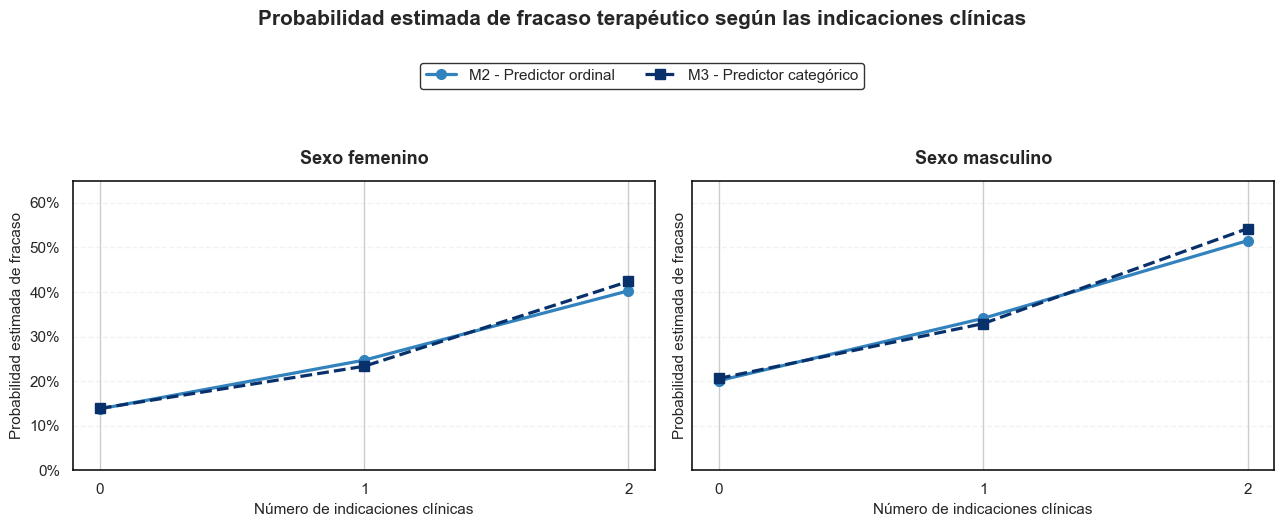

In [15]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

configuraciones = [
    ("Femenino", axes[0]),
    ("Masculino", axes[1])
]

modelos_grafico = [
    ("Probabilidad M2 (%)", "M2 - Predictor ordinal", "#3182BD", "o", "-"),
    ("Probabilidad M3 (%)", "M3 - Predictor categórico", "#08306B", "s", "--")
]

for sexo, ax in configuraciones:
    datos = perfiles.loc[
        perfiles["Sexo"] == sexo
    ].sort_values("N_INDICACIONES")

    for columna, etiqueta, color, marcador, estilo in modelos_grafico:
        ax.plot(
            datos["N_INDICACIONES"],
            datos[columna] / 100,
            color=color,
            marker=marcador,
            linestyle=estilo,
            linewidth=2.3,
            markersize=7,
            label=etiqueta
        )

    ax.set_title(
        f"Sexo {sexo.lower()}",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Número de indicaciones clínicas", fontsize=11)
    ax.set_ylabel("Probabilidad estimada de fracaso", fontsize=11)
    ax.set_xticks([0, 1, 2])
    ax.set_ylim(0, 0.65)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", linestyle="--", alpha=0.25)

    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1.1)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=2,
    frameon=True,
    edgecolor="black"
)

fig.suptitle(
    "Probabilidad estimada de fracaso terapéutico según las indicaciones clínicas",
    fontsize=15,
    fontweight="bold",
    y=1.05
)

plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()


Las probabilidades estimadas muestran un aumento progresivo del fracaso terapéutico conforme se incrementa el número de indicaciones clínicas. En los procedimientos correspondientes al perfil femenino, la probabilidad pasa de aproximadamente un 14 % en ausencia de indicaciones a un 40–43 % cuando se presentan ambas. Para el perfil masculino, aumenta de alrededor del 20 % hasta superar el 50 %.

Las trayectorias de M2 y M3 son muy similares en ambos perfiles. Esto indica que tratar el número de indicaciones como una variable ordinal o mediante categorías independientes produce estimaciones próximas para las combinaciones evaluadas. Las diferencias más visibles aparecen cuando se presentan ambas indicaciones, aunque no superan unos pocos puntos porcentuales.

También se observa que las probabilidades estimadas son mayores para el perfil masculino en los tres niveles de indicaciones. Sin embargo, esta diferencia no debe interpretarse como una asociación estadísticamente confirmada del sexo con el fracaso terapéutico, dado que sus intervalos de confianza incluyen la unidad.

Esto permite apreciar la relación positiva entre el número de indicaciones clínicas y la probabilidad estimada de fracaso terapéutico, así como la similitud de los resultados obtenidos con las dos especificaciones del predictor.


### 3.6. Evaluación del desempeño del modelo principal

Una vez examinadas las asociaciones entre las indicaciones clínicas y el fracaso terapéutico, se evalúa el desempeño del modelo principal M2.

Se consideran tres métricas complementarias: el área bajo la curva ROC (ROC-AUC), que cuantifica la capacidad de discriminación; el Brier Score, que mide el error cuadrático medio de las probabilidades estimadas; y la pérdida logarítmica (*log-loss*), que penaliza las predicciones probabilísticas incorrectas, especialmente cuando se realizan con elevada confianza.

El ROC-AUC toma valores entre 0 y 1, donde 0.5 representa una discriminación equivalente al azar. Para el Brier Score y la pérdida logarítmica, los valores menores indican un mejor desempeño.

Las métricas se calculan inicialmente sobre la cohorte utilizada para estimar los parámetros. En consecuencia, representan el desempeño aparente del modelo y pueden presentar optimismo. Su interpretación definitiva requiere una evaluación posterior mediante validación interna.


In [16]:

from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss

probabilidades_m2 = expit(
    X_m2.to_numpy() @ resultado_m2["coeficientes"]
)

prevalencia = y.mean()

tabla_desempeno = pd.DataFrame({
    "Métrica": [
        "ROC-AUC",
        "Brier Score",
        "Brier Score de referencia",
        "Log-loss",
        "Log-loss de referencia"
    ],
    "Resultado": [
        roc_auc_score(y, probabilidades_m2),
        brier_score_loss(y, probabilidades_m2),
        brier_score_loss(y, np.full(len(y), prevalencia)),
        log_loss(y, probabilidades_m2),
        log_loss(y, np.full(len(y), prevalencia))
    ]
})

display(
    tabla_desempeno.style
    .hide(axis="index")
    .format({"Resultado": "{:.4f}"})
    .set_caption("Desempeño aparente del modelo principal M2")
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)


Métrica,Resultado
ROC-AUC,0.6039
Brier Score,0.1477
Brier Score de referencia,0.1558
Log-loss,0.4689
Log-loss de referencia,0.4907



#### 3.6.1. Análisis de discriminación mediante la curva ROC

La capacidad de discriminación del modelo principal M2 se examina mediante la curva ROC (*Receiver Operating Characteristic*), que representa la sensibilidad frente a la tasa de falsos positivos para diferentes umbrales de clasificación.

El área bajo la curva (ROC-AUC) resume la capacidad del modelo para asignar mayores probabilidades estimadas a los procedimientos que presentan fracaso terapéutico en comparación con aquellos que no presentan el desenlace.

Como referencia, se incorpora la diagonal correspondiente a un clasificador sin capacidad discriminativa (AUC = 0.5).

La curva se calcula sobre la cohorte utilizada para ajustar el modelo y, por tanto, representa su capacidad de discriminación aparente, pendiente de validación interna.


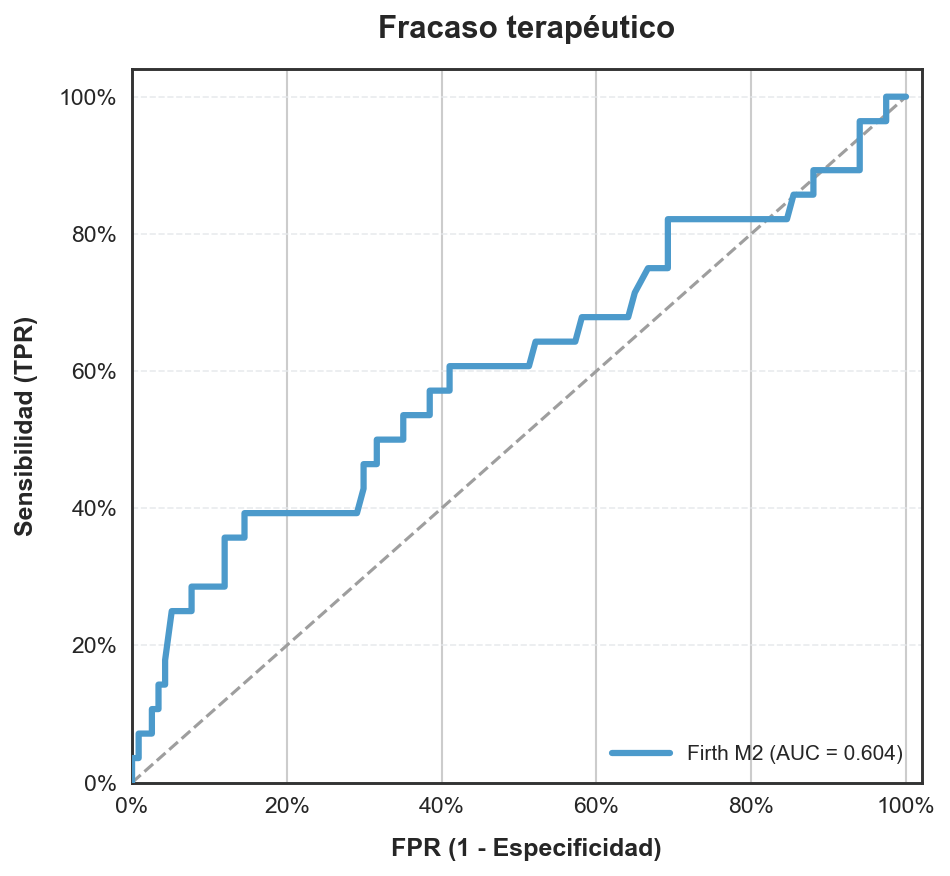

In [17]:

from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt
import numpy as np

fpr, tpr, _ = roc_curve(y, probabilidades_m2)
auc_m2 = roc_auc_score(y, probabilidades_m2)

fig, ax = plt.subplots(figsize=(6.5, 6), dpi=150)

ax.plot(
    fpr,
    tpr,
    color="#4C9ACB",
    linewidth=3,
    label=f"Firth M2 (AUC = {auc_m2:.3f})",
    zorder=3
)

ax.plot(
    [0, 1],
    [0, 1],
    color="#9E9E9E",
    linewidth=1.5,
    linestyle="--",
    zorder=2
)

ax.set_title(
    "Fracaso terapéutico",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "FPR (1 - Especificidad)",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel(
    "Sensibilidad (TPR)",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.04)

ax.set_xticks(np.linspace(0, 1, 6))
ax.set_yticks(np.linspace(0, 1, 6))

ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

ax.tick_params(
    axis="both",
    labelsize=11,
    length=0,
    pad=7
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    color="#E5E7EB",
    alpha=0.85
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#333333")
    spine.set_linewidth(1.4)

ax.legend(
    loc="lower right",
    fontsize=10,
    frameon=False,
    handlelength=2.8
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()
plt.show()






La curva ROC del modelo de regresión logística de Firth ajustado (M2) presenta un área bajo la curva (AUC) de 0.6039, lo que indica una capacidad discriminativa limitada para diferenciar los procedimientos que presentan fracaso terapéutico de aquellos que no presentan este desenlace.

La curva se sitúa predominantemente por encima de la diagonal de referencia, aunque mantiene una proximidad considerable con ella en distintos segmentos. Esto evidencia que el modelo presenta cierta capacidad de discriminación, pero no logra una separación clara entre ambos grupos.

Desde una perspectiva probabilística, el AUC obtenido indica que, al seleccionar aleatoriamente un procedimiento con fracaso terapéutico y otro sin fracaso, el modelo tiene aproximadamente un 60.39 % de probabilidad de asignar una puntuación de riesgo superior al procedimiento con fracaso, considerando los empates.

Estos resultados sugieren que las variables incluidas en M2 —número de indicaciones clínicas, edad y sexo— aportan información limitada para la discriminación individual del desenlace. Sin embargo, esta capacidad discriminativa no contradice la asociación estadística identificada previamente entre el número de indicaciones y el fracaso terapéutico.

Finalmente, dado que la curva se construye utilizando los mismos 145 procedimientos empleados para ajustar el modelo, el AUC corresponde al desempeño aparente y puede presentar optimismo. Por tanto, su capacidad de generalización deberá examinarse mediante validación interna.



#### 3.6.2. Evaluación de la calibración del modelo

La calibración permite evaluar la concordancia entre las probabilidades estimadas por el modelo y la frecuencia observada del fracaso terapéutico.

A diferencia de la discriminación, que examina la capacidad para ordenar los procedimientos según su riesgo, la calibración se centra en la correspondencia entre las probabilidades predichas y los desenlaces observados.

Para evaluar esta propiedad, se construye una curva de calibración que compara las probabilidades estimadas con las proporciones observadas de fracaso terapéutico. La diagonal representa la calibración perfecta, en la cual ambas cantidades coinciden.

Debido al tamaño de la cohorte y al número limitado de eventos, se emplea una agrupación en cuatro categorías de riesgo estimado. Esta representación permite realizar una evaluación descriptiva inicial, aunque sus resultados pueden depender de la agrupación seleccionada.

La calibración se evalúa inicialmente sobre los mismos procedimientos utilizados para ajustar el modelo, por lo que los resultados corresponden al desempeño aparente y deberán interpretarse junto con la validación interna posterior.


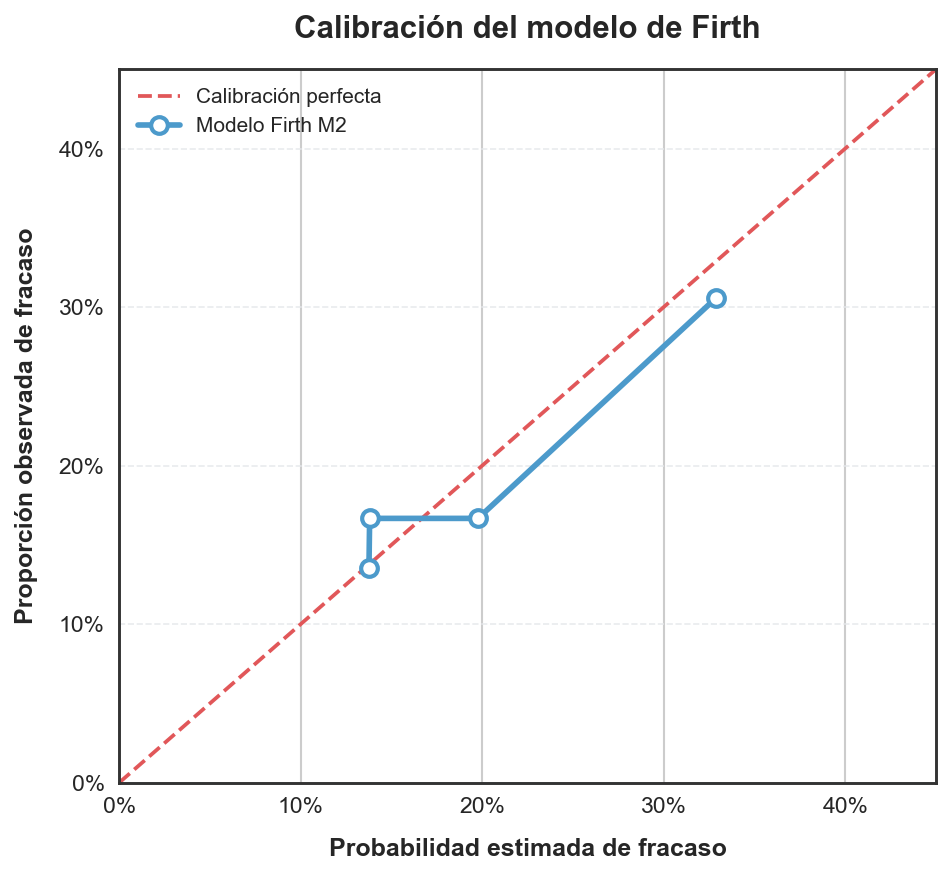

In [18]:

from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df_calibracion = pd.DataFrame({
    "Observado": y.to_numpy(),
    "Probabilidad": probabilidades_m2
})

df_calibracion["Grupo"] = pd.qcut(
    df_calibracion["Probabilidad"].rank(method="first"),
    q=4,
    labels=False
)

resumen_calibracion = (
    df_calibracion
    .groupby("Grupo", observed=True)
    .agg(
        Probabilidad_estimada=("Probabilidad", "mean"),
        Proporcion_observada=("Observado", "mean"),
        Procedimientos=("Observado", "size"),
        Fracasos=("Observado", "sum")
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(6.5, 6), dpi=150)

ax.plot(
    [0, 1],
    [0, 1],
    color="#E15759",
    linewidth=1.8,
    linestyle="--",
    label="Calibración perfecta",
    zorder=2
)

ax.plot(
    resumen_calibracion["Probabilidad_estimada"],
    resumen_calibracion["Proporcion_observada"],
    color="#4C9ACB",
    linewidth=2.7,
    marker="o",
    markersize=8,
    markerfacecolor="white",
    markeredgewidth=2,
    label="Modelo Firth M2",
    zorder=3
)

ax.set_title(
    "Calibración del modelo de Firth",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Probabilidad estimada de fracaso",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel(
    "Proporción observada de fracaso",
    fontsize=12,
    fontweight="bold",
    labelpad=10
)

ax.set_xlim(0, 0.45)
ax.set_ylim(0, 0.45)

ax.set_xticks(np.arange(0, 0.46, 0.10))
ax.set_yticks(np.arange(0, 0.46, 0.10))

ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))

ax.tick_params(
    axis="both",
    labelsize=11,
    length=0,
    pad=7
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.8,
    color="#E5E7EB",
    alpha=0.85
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#333333")
    spine.set_linewidth(1.4)

ax.legend(
    loc="upper left",
    fontsize=10,
    frameon=False
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.tight_layout()
plt.show()





La curva de calibración del modelo de regresión logística de Firth ajustado (M2) muestra una correspondencia aproximada entre las probabilidades estimadas de fracaso terapéutico y las proporciones observadas en los cuatro grupos evaluados.

Las probabilidades medias estimadas se concentran entre aproximadamente el 14 % y el 33 %. En los grupos de menor riesgo se identifican proporciones observadas cercanas al 14 % y 17 %, a pesar de presentar probabilidades estimadas similares. Esta diferencia refleja cierta variabilidad en los desenlaces observados entre grupos con niveles de riesgo próximos.

En los grupos con probabilidades estimadas cercanas al 20 % y 33 %, las proporciones observadas se sitúan ligeramente por debajo de los valores predichos, lo que sugiere una sobreestimación moderada del riesgo en estos segmentos.

En conjunto, los resultados muestran una concordancia descriptiva razonable entre las probabilidades estimadas y las frecuencias observadas, aunque se identifican desviaciones respecto a la diagonal de calibración perfecta.

La interpretación debe considerar que la representación se construye mediante cuatro grupos de procedimientos y que la cohorte registra únicamente 28 eventos de fracaso terapéutico. Por tanto, las proporciones observadas pueden presentar variabilidad considerable y la agrupación puede ocultar diferencias individuales.

Adicionalmente, la evaluación se realiza sobre los mismos procedimientos utilizados para ajustar el modelo, por lo que no permite establecer su calibración en observaciones independientes. En consecuencia, los resultados deben interpretarse como una evaluación descriptiva preliminar, pendiente de validación interna.





### 3.7. Validación interna mediante bootstrap

La evaluación inicial del modelo M2 se realiza sobre los mismos procedimientos utilizados para estimar sus parámetros. En consecuencia, las métricas obtenidas pueden presentar optimismo y sobreestimar el desempeño esperado en observaciones no utilizadas durante el ajuste.

Para examinar este comportamiento, se implementa una validación interna mediante bootstrap con corrección del optimismo.

El procedimiento consiste en generar muestras aleatorias con reemplazo a partir de la cohorte original, ajustar nuevamente el modelo de regresión logística de Firth en cada muestra y calcular su desempeño tanto en la muestra bootstrap como en la cohorte original.

Para cada repetición, el optimismo se define como:

$$
O_b = M_b^{\mathrm{bootstrap}} - M_b^{\mathrm{original}}
$$

donde $M_b$ representa la métrica de desempeño correspondiente a la repetición $b$.

El optimismo promedio se obtiene mediante:

$$
\overline{O} = \frac{1}{B}\sum_{b=1}^{B} O_b
$$

Finalmente, la estimación corregida se calcula como:

$$
M_{\mathrm{corregida}} =
M_{\mathrm{aparente}}-\overline{O}
$$

Este procedimiento se aplica al ROC-AUC, Brier Score y pérdida logarítmica. Para las métricas de error, un valor de optimismo negativo indica que el error es menor en la muestra de ajuste que en la cohorte original.

La validación interna permite estimar el optimismo asociado al proceso de ajuste, aunque no sustituye una validación externa con datos independientes.


In [19]:

from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from scipy.special import expit
import numpy as np
import pandas as pd

B = 500
semilla = 42
rng = np.random.default_rng(semilla)

X_original = X_m2.to_numpy(dtype=float)
y_original = y.to_numpy(dtype=int)

metricas = ["ROC-AUC", "Brier Score", "Log-loss"]

def evaluar_desempeno(y_real, probabilidades):
    return np.array([
        roc_auc_score(y_real, probabilidades),
        brier_score_loss(y_real, probabilidades),
        log_loss(y_real, probabilidades, labels=[0, 1])
    ])

desempeno_aparente = evaluar_desempeno(
    y_original,
    expit(X_original @ resultado_m2["coeficientes"])
)

resultados_bootstrap = []
intentos_fallidos = 0

for b in range(B):
    indices = rng.choice(
        len(y_original),
        size=len(y_original),
        replace=True
    )

    X_boot = X_original[indices]
    y_boot = y_original[indices]

    if len(np.unique(y_boot)) < 2:
        intentos_fallidos += 1
        continue

    if np.linalg.matrix_rank(X_boot) != X_boot.shape[1]:
        intentos_fallidos += 1
        continue

    try:
        ajuste_boot = ajustar_firth_gradiente(X_boot, y_boot)

        if not ajuste_boot["convergencia"]:
            intentos_fallidos += 1
            continue

        beta_boot = ajuste_boot["coeficientes"]

        prob_boot = expit(X_boot @ beta_boot)
        prob_original = expit(X_original @ beta_boot)

        desempeno_boot = evaluar_desempeno(
            y_boot,
            prob_boot
        )

        desempeno_original = evaluar_desempeno(
            y_original,
            prob_original
        )

        resultados_bootstrap.append(
            desempeno_boot - desempeno_original
        )

    except (ValueError, np.linalg.LinAlgError, RuntimeError, FloatingPointError):
        intentos_fallidos += 1

resultados_bootstrap = np.asarray(resultados_bootstrap)

if len(resultados_bootstrap) == 0:
    raise RuntimeError(
        "No se obtuvieron repeticiones bootstrap válidas."
    )

optimismo_promedio = resultados_bootstrap.mean(axis=0)

desempeno_corregido = (
    desempeno_aparente - optimismo_promedio
)

tabla_validacion = pd.DataFrame({
    "Métrica": metricas,
    "Aparente": desempeno_aparente,
    "Optimismo promedio": optimismo_promedio,
    "Corregido": desempeno_corregido
})

print(f"Repeticiones solicitadas: {B}")
print(f"Repeticiones válidas: {len(resultados_bootstrap)}")
print(f"Repeticiones descartadas: {intentos_fallidos}")

display(
    tabla_validacion.style
    .hide(axis="index")
    .format({
        "Aparente": "{:.4f}",
        "Optimismo promedio": "{:+.4f}",
        "Corregido": "{:.4f}"
    })
    .set_caption(
        "Validación interna bootstrap del modelo de Firth M2"
    )
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#17365D"),
                ("color", "white"),
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center"),
                ("border", "1px solid black"),
                ("padding", "8px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("text-align", "center"),
                ("font-weight", "bold"),
                ("padding", "10px")
            ]
        }
    ])
)


Repeticiones solicitadas: 500
Repeticiones válidas: 487
Repeticiones descartadas: 13


Métrica,Aparente,Optimismo promedio,Corregido
ROC-AUC,0.6039,+0.0439,0.5600
Brier Score,0.1477,-0.0097,0.1574
Log-loss,0.4689,-0.0283,0.4972




La validación interna mediante bootstrap se realiza con 500 repeticiones, de las cuales 487 (97.4 %) producen ajustes válidos. Las 13 repeticiones restantes (2.6 %) se descartan por problemas de convergencia u otras condiciones numéricas, lo que evidencia algunas dificultades de estabilidad durante el remuestreo.

El ROC-AUC disminuye de 0.6039 en la evaluación aparente a 0.5600 después de aplicar la corrección del optimismo, correspondiente a una reducción de 0.0439. Este resultado indica que parte de la capacidad discriminativa observada inicialmente puede atribuirse al ajuste del modelo sobre la cohorte utilizada para su estimación.

El Brier Score aumenta de 0.1477 a 0.1574 después de la corrección, mientras que la pérdida logarítmica pasa de 0.4689 a 0.4972. Estos incrementos reflejan un deterioro de la precisión probabilística estimada al considerar el optimismo asociado al proceso de ajuste.

Adicionalmente, los valores corregidos del Brier Score y la pérdida logarítmica son ligeramente superiores a los obtenidos mediante una predicción constante basada en la prevalencia observada (0.1558 y 0.4907, respectivamente). Esta comparación descriptiva no muestra una ventaja predictiva clara del modelo ajustado frente a dicha referencia.

En conjunto, los resultados indican que el modelo M2 presenta una capacidad predictiva limitada, especialmente después de la corrección del optimismo. Sin embargo, estos hallazgos no invalidan las asociaciones estadísticas identificadas mediante la regresión logística de Firth, dado que la evaluación inferencial y la evaluación predictiva responden a objetivos diferentes.

Por tanto, M2 se mantiene como modelo principal para el análisis exploratorio de la asociación entre el número de indicaciones clínicas y el fracaso terapéutico, sin considerarse una herramienta suficientemente validada para la predicción clínica individual.

Finalmente, los resultados deben interpretarse teniendo en cuenta el número limitado de eventos, las repeticiones bootstrap descartadas y el supuesto de independencia entre procedimientos. La validación interna no sustituye una evaluación externa en una cohorte independiente.


## 4. Conclusiones

Se implementaron tres modelos de regresión logística penalizada de Firth para evaluar la asociación entre las indicaciones clínicas y el fracaso terapéutico en procedimientos de CPRE asistidos por SpyGlass. El análisis incluyó 145 procedimientos, de los cuales 28 (19.3 %) presentaron fracaso terapéutico. Se consideraron dos indicaciones principales: estenosis u obstrucción biliar y neoplasia o sospecha neoplásica, incorporando la edad y el sexo como covariables de ajuste.

Los resultados identificaron una asociación estadísticamente significativa entre el número de indicaciones clínicas y el fracaso terapéutico. En el modelo sin ajustar (M1), cada indicación adicional se asoció con un incremento de aproximadamente 2.11 veces en las *odds* de fracaso (OR = 2.107; IC del 95 %: 1.132–3.905; p = 0.0195). Esta asociación se mantuvo después de ajustar por edad y sexo en M2 (OR = 2.055; IC del 95 %: 1.077–3.896; p = 0.0296). Ninguna de las dos covariables demográficas presentó una asociación estadísticamente significativa con el desenlace.

El análisis de sensibilidad mediante una especificación categórica del número de indicaciones (M3) permitió examinar esta relación con mayor detalle. Los procedimientos que presentaron ambas indicaciones registraron unas *odds* estimadas de fracaso terapéutico 4.56 veces mayores que aquellos sin ninguna de ellas (IC del 95 %: 1.099–18.419; p = 0.0374). Para los procedimientos con una sola indicación no se encontró una asociación estadísticamente significativa. La amplitud de los intervalos de confianza, especialmente en M3, refleja la incertidumbre existente sobre la magnitud de estas asociaciones.

La comparación de las probabilidades estimadas mostró un incremento progresivo del fracaso terapéutico conforme aumentó el número de indicaciones clínicas. Las trayectorias de M2 y M3 fueron similares para los perfiles evaluados, con diferencias máximas de 2.71 puntos porcentuales. Este comportamiento respalda la elección de M2 como modelo principal por su menor complejidad, conservando M3 como una especificación complementaria para examinar la consistencia de los resultados.

La evaluación del desempeño mostró que la asociación estadística identificada no se traduce necesariamente en una buena capacidad predictiva. El modelo M2 obtuvo un ROC-AUC aparente de 0.6039, que disminuyó a 0.5600 después de la corrección del optimismo mediante 500 repeticiones bootstrap, de las cuales 487 produjeron ajustes válidos. La curva de calibración mostró una concordancia aproximada entre las probabilidades estimadas y las frecuencias observadas, aunque con algunas desviaciones. Los valores corregidos del Brier Score y la pérdida logarítmica tampoco evidenciaron una ventaja clara frente a una predicción constante basada en la prevalencia del desenlace.

La principal limitación del estudio fue el número reducido de eventos de fracaso terapéutico, que restringe la precisión de las estimaciones y la evaluación del desempeño. También debe considerarse que el indicador de indicaciones clínicas reúne dos condiciones diferentes y no permite establecer cuál de ellas contribuye individualmente a la asociación observada. Adicionalmente, no fue posible verificar si todos los procedimientos correspondían a pacientes independientes.

En conclusión, **el número de indicaciones clínicas presentó una asociación positiva y estadísticamente significativa con el fracaso terapéutico en la cohorte analizada**, incluso después del ajuste por edad y sexo. La presencia simultánea de estenosis u obstrucción biliar y neoplasia o sospecha neoplásica se relacionó con mayores *odds* estimadas de fracaso. Estos resultados aportan evidencia exploratoria sobre las características clínicas asociadas al desenlace, pero no permiten establecer relaciones causales. Aunque M2 constituye una especificación adecuada para estudiar esta asociación, su capacidad discriminativa limitada impide considerarlo una herramienta validada para la predicción clínica individual.